# 01 · Cadrage et exploration des données

**Projet** : prédire les joueurs qui vont quitter un MMO par abonnement (churn), pour cibler les offres de rétention.

**Décision éclairée** : à une date de coupure, choisir à quels joueurs actifs envoyer une offre (mois gratuit, bonus).
**Cible** : `churn_3m` = 1 si un joueur actif dans les 30 jours avant la coupure n'apparaît plus du tout dans les 3 mois suivants.
**Données** : World of Warcraft Avatar History (Lee et al., 2011), relevés de connexion d'un serveur sur toute l'année 2008.

Ce notebook couvre l'axe 3 : description, qualité, choix des périodes, construction de la cible, relations avec la cible et audit de fuite.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# Racine du projet
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from features import build_dataset, load_raw

FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.figsize": (8, 4), "axes.spines.top": False, "axes.spines.right": False})

## 1. Chargement

In [2]:
n_brut = sum(1 for _ in open(ROOT / "data" / "wowah_data.csv")) - 1  # lignes hors en-tête
df = load_raw()  # supprime aussi les doublons exacts
print(f"Lignes brutes : {n_brut:,}")
print(f"Doublons exacts supprimés : {n_brut - len(df):,}")
print(f"Lignes conservées : {len(df):,}")
print(f"Personnages distincts : {df['char'].nunique():,}")
print(f"Période : {df['timestamp'].min()} → {df['timestamp'].max()}")
df.head()

Lignes brutes : 10,826,734
Doublons exacts supprimés : 3,557
Lignes conservées : 10,823,177
Personnages distincts : 37,354
Période : 2008-01-01 00:02:04 → 2008-12-31 23:50:18


,char,level,race,charclass,zone,guild,timestamp
0,59425,1,Orc,Rogue,Orgrimmar,165,2008-01-01 00:02:04
1,65494,9,Orc,Hunter,Durotar,-1,2008-01-01 00:02:04
2,65325,14,Orc,Warrior,Ghostlands,-1,2008-01-01 00:02:04
3,65490,18,Orc,Hunter,Ghostlands,-1,2008-01-01 00:02:04
4,2288,60,Orc,Hunter,Hellfire Peninsula,-1,2008-01-01 00:02:09


**Lecture** : 10,8 millions de relevés sur toute l'année 2008. 3 557 lignes sont des doublons exacts (même personnage, même seconde) : ce sont des relevés enregistrés deux fois, on les supprime. Il reste 37 354 personnages distincts.

## 2. Dictionnaire des variables

| Variable | Type | Unité / valeurs | Signification |
| --- | --- | --- | --- |
| `char` | entier | identifiant anonymisé | Personnage (avatar) observé |
| `level` | entier | 1 à 80 | Niveau du personnage au moment du relevé |
| `race` | catégorie | 5 races Horde | Race du personnage |
| `charclass` | catégorie | 10 classes | Classe du personnage |
| `zone` | catégorie | nom de zone | Lieu du jeu où se trouve le personnage |
| `guild` | entier | identifiant anonymisé, -1 = aucune | Guilde du personnage |
| `timestamp` | date-heure | à la seconde | Moment du relevé (≈ toutes les 10 min, via la commande /who) |

Chaque ligne signifie : « ce personnage était connecté à ce moment-là ». Un relevé représente donc environ 10 minutes de jeu.

## 3. Qualité des données

In [3]:
print("Valeurs manquantes par colonne :")
print(df.isna().sum().to_string())
print(f"\nPart des relevés sans guilde (guild = -1) : {df['guild'].eq(-1).mean():.1%}")
print(f"Niveau : min {df['level'].min()}, médiane {df['level'].median():.0f}, max {df['level'].max()}")
print("\nClasses :", df["charclass"].value_counts().to_dict())

Valeurs manquantes par colonne :
char         0
level        0
race         0
charclass    0
zone         0
guild        0
timestamp    0

Part des relevés sans guilde (guild = -1) : 15.6%
Niveau : min 1, médiane 70, max 80

Classes : {'Hunter': 1549395, 'Mage': 1437487, 'Warlock': 1346988, 'Warrior': 1282021, 'Paladin': 1158324, 'Priest': 1126701, 'Rogue': 1049787, 'Druid': 916008, 'Shaman': 726405, 'Death Knight': 230061}


**Lecture** :
- Aucune valeur manquante au sens strict. En revanche, `guild = -1` code l'absence de guilde (15,6 % des relevés). Ce n'est pas une donnée manquante, c'est une information : on la transforme en variable `en_guilde`.
- Le niveau monte jusqu'à 80, et la classe Death Knight apparaît. Les deux n'existent qu'après la sortie de l'extension *Wrath of the Lich King* (13 novembre 2008). Les règles du jeu changent à ce moment-là : on évite cette période pour construire le modèle.

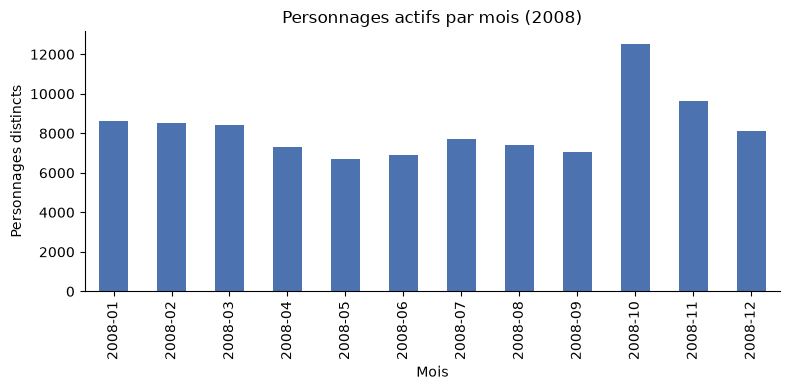

timestamp
2008-01     8600
2008-02     8535
2008-03     8429
2008-04     7310
2008-05     6677
2008-06     6918
2008-07     7714
2008-08     7425
2008-09     7056
2008-10    12535
2008-11     9660
2008-12     8113
Freq: M, Name: char, dtype: int64

In [4]:
mensuel = df.groupby(df["timestamp"].dt.to_period("M"))["char"].nunique()
ax = mensuel.plot(kind="bar", color="#4C72B0")
ax.set_title("Personnages actifs par mois (2008)")
ax.set_xlabel("Mois")
ax.set_ylabel("Personnages distincts")
plt.tight_layout()
plt.savefig(FIG / "01_actifs_par_mois.png", dpi=150)
plt.show()
mensuel

**Lecture** : l'activité baisse au printemps (minimum en mai, environ 6 700 personnages), puis explose en octobre (environ 12 500) avec la mise à jour qui prépare l'extension. Octobre à décembre ne ressemble donc pas au reste de l'année.

**Décision** : on construit la cible sur des périodes antérieures à octobre, avec un **découpage chronologique** :
- **Entraînement** : coupure au 1er avril, cible observée d'avril à juin.
- **Test** : coupure au 1er juillet, cible observée de juillet à septembre. Le modèle est ainsi évalué sur une période future qu'il n'a jamais vue, comme en conditions réelles.

Le jeu de test n'est **pas** exploré ici : toute l'analyse qui suit porte sur la coupure d'entraînement.

## 4. Construction de la cible (coupure d'entraînement)

Joueurs actifs dans les 30 jours avant le 1er avril : 8,265
Taux de churn (aucune connexion d'avril à juin) : 31.4%


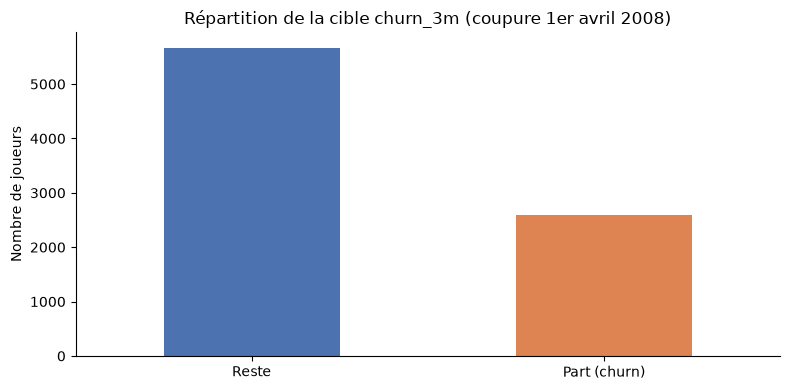

,char,anciennete_j,jours_depuis_derniere_co,releves_7j,releves_30j,releves_30j_precedents,jours_actifs_30j,zones_distinctes_30j,niveau,gain_niveau_30j,en_guilde,nb_guildes,race,classe,tendance_activite,churn_3m,date_coupure
0,59425,89,2.970289,2.0,7,6.0,4,1,1,0,1,1.0,Orc,Rogue,1.000000,0,2008-04-01
1,64820,87,15.202685,0.0,27,34.0,12,1,1,0,0,0.0,Orc,Rogue,0.771429,1,2008-04-01
2,66981,66,11.966389,0.0,201,216.0,19,6,12,0,1,1.0,Orc,Warlock,0.926267,0,2008-04-01
3,66102,81,11.126481,0.0,14,618.0,4,2,49,0,1,1.0,Orc,Shaman,0.022617,0,2008-04-01
4,63829,89,0.005347,12.0,122,268.0,17,15,53,8,1,1.0,Orc,Hunter,0.453532,0,2008-04-01


In [5]:
train = build_dataset(df, "2008-04-01")
print(f"Joueurs actifs dans les 30 jours avant le 1er avril : {len(train):,}")
print(f"Taux de churn (aucune connexion d'avril à juin) : {train['churn_3m'].mean():.1%}")

ax = train["churn_3m"].map({0: "Reste", 1: "Part (churn)"}).value_counts().plot(kind="bar", color=["#4C72B0", "#DD8452"])
ax.set_title("Répartition de la cible churn_3m (coupure 1er avril 2008)")
ax.set_ylabel("Nombre de joueurs")
ax.set_xlabel("")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(FIG / "02_cible.png", dpi=150)
plt.show()
train.head()

**Lecture** : 8 265 joueurs étaient actifs en mars, et 31,4 % d'entre eux ne se reconnectent plus jamais d'avril à juin. La classe « part » est minoritaire sans être rare. Conséquence : l'accuracy ne sera pas la métrique principale. On suivra le Recall, la Precision et la PR-AUC.

## 5. Relations entre les variables et la cible

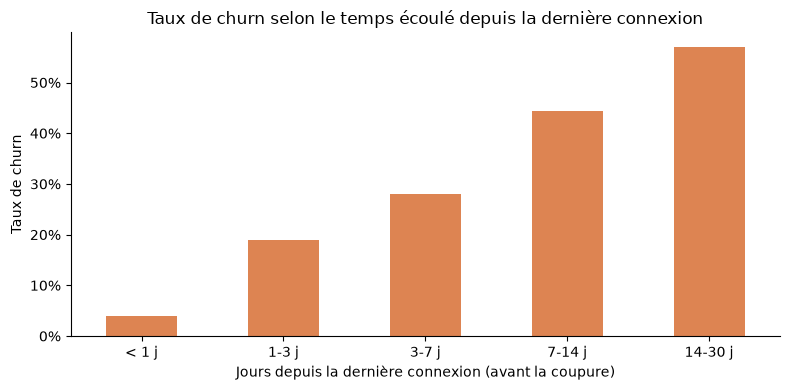

jours_depuis_derniere_co
< 1 j      0.039567
1-3 j      0.188612
3-7 j      0.280447
7-14 j     0.443722
14-30 j    0.570499
Name: churn_3m, dtype: float64

In [6]:
tranches = pd.cut(train["jours_depuis_derniere_co"], [0, 1, 3, 7, 14, 30],
                  labels=["< 1 j", "1-3 j", "3-7 j", "7-14 j", "14-30 j"])
taux = train.groupby(tranches, observed=True)["churn_3m"].mean()
ax = taux.plot(kind="bar", color="#DD8452")
ax.set_title("Taux de churn selon le temps écoulé depuis la dernière connexion")
ax.set_xlabel("Jours depuis la dernière connexion (avant la coupure)")
ax.set_ylabel("Taux de churn")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(FIG / "03_churn_recence.png", dpi=150)
plt.show()
taux

**Lecture** : un joueur vu dans les dernières 24 h ne part que dans 4 % des cas, contre 57 % pour un joueur absent depuis 14 à 30 jours. La récence est le signal le plus intuitif. C'est d'ailleurs la règle métier actuelle (« relancer les joueurs absents depuis 14 jours »), qui servira de baseline : le modèle devra faire mieux.

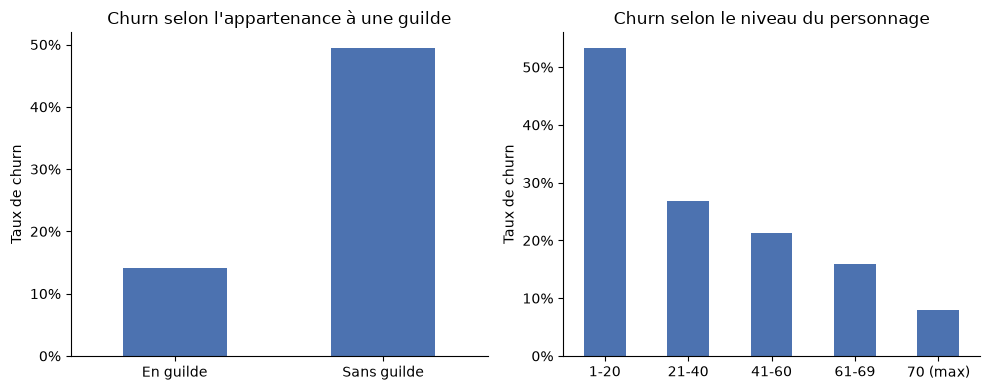

en_guilde
En guilde      0.140655
Sans guilde    0.494937
Name: churn_3m, dtype: float64


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
g = train.groupby(train["en_guilde"].map({0: "Sans guilde", 1: "En guilde"}))["churn_3m"].mean()
g.plot(kind="bar", ax=axes[0], color="#4C72B0")
axes[0].set_title("Churn selon l'appartenance à une guilde")
niv = pd.cut(train["niveau"], [0, 20, 40, 60, 69, 70], labels=["1-20", "21-40", "41-60", "61-69", "70 (max)"])
train.groupby(niv, observed=True)["churn_3m"].mean().plot(kind="bar", ax=axes[1], color="#4C72B0")
axes[1].set_title("Churn selon le niveau du personnage")
for ax in axes:
    ax.set_xlabel("")
    ax.set_ylabel("Taux de churn")
    ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
    ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.savefig(FIG / "04_churn_guilde_niveau.png", dpi=150)
plt.show()
print(g)

**Lecture** :
- **Guilde** : 14 % de churn en guilde contre 49 % sans. Le lien social retient les joueurs, ce qui est un levier actionnable : on peut inciter un joueur isolé à rejoindre une guilde.
- **Niveau** : 53 % de churn sous le niveau 20, contre 8 % au niveau maximum (70). Beaucoup de personnages de bas niveau sont des débutants qui testent le jeu, ou des personnages secondaires abandonnés. C'est la limite « un personnage n'est pas un joueur », à discuter dans les risques.

              taux_churn  effectif
anciennete_j                      
0-15 j          0.610569      1230
16-30 j         0.661367      1258
31-60 j         0.296763      1112
61-90 j         0.146624      4665


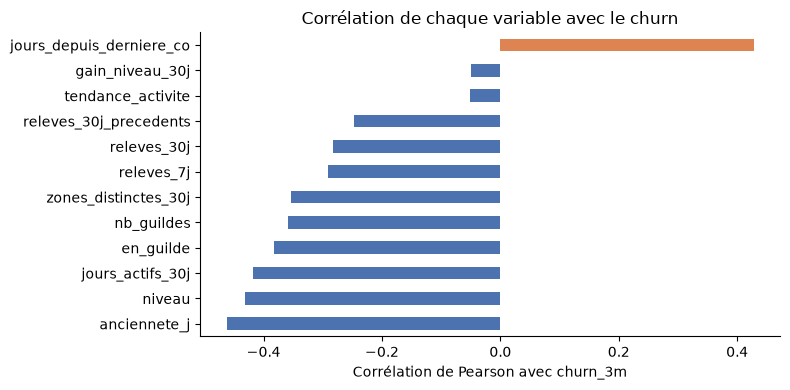

In [8]:
anc = pd.cut(train["anciennete_j"], [-1, 15, 30, 60, 90], labels=["0-15 j", "16-30 j", "31-60 j", "61-90 j"])
print(train.groupby(anc, observed=True)["churn_3m"].agg(taux_churn="mean", effectif="size"))

num = train.select_dtypes("number").drop(columns=["char", "churn_3m"])
corr = num.corrwith(train["churn_3m"]).sort_values()
ax = corr.plot(kind="barh", color=["#DD8452" if v > 0 else "#4C72B0" for v in corr])
ax.set_title("Corrélation de chaque variable avec le churn")
ax.set_xlabel("Corrélation de Pearson avec churn_3m")
plt.tight_layout()
plt.savefig(FIG / "05_correlations.png", dpi=150)
plt.show()

**Lecture** :
- Les personnages apparus depuis moins de 30 jours partent dans plus de 60 % des cas, contre 15 % pour ceux présents depuis plus de 60 jours. Les premières semaines sont la période la plus risquée.
- Les variables les plus liées au churn sont l'ancienneté, le niveau, le nombre de jours actifs et la récence. La tendance d'activité et le gain de niveau sont peu corrélés *linéairement*. Un modèle à base d'arbres pourra quand même capter des effets non linéaires ou des interactions (par exemple, une baisse d'activité chez un joueur ancien).

## 6. Audit de fuite de données

| Élément | Risque | Décision |
| --- | --- | --- |
| Relevés après la coupure | Ils contiennent la réponse | Utilisés **uniquement** pour construire la cible, jamais dans les variables |
| Coupure d'entraînement vs coupure de test | Mélanger les périodes ferait servir le futur à prédire le passé | Découpage chronologique : avril pour l'entraînement, juillet pour le test |
| `char` (identifiant) | Aucune signification métier, risque de mémorisation | Exclu du modèle |
| `date_coupure` | Constante dans chaque jeu | Exclue du modèle |
| Fenêtre d'historique | Une fenêtre plus longue au test qu'à l'entraînement fausserait l'ancienneté | Fenêtre fixe de 90 jours avant chaque coupure |
| Période après octobre 2008 | Nouvelle extension : niveau 80, nouvelle classe | Hors des périodes utilisées |

## 7. Variables construites

| Variable | Construction | Justification métier |
| --- | --- | --- |
| `jours_depuis_derniere_co` | Coupure − dernier relevé | Un joueur qui ne se connecte plus est en train de partir |
| `jours_actifs_30j` | Nombre de jours distincts avec au moins un relevé | Mesure la régularité, plus robuste qu'un volume horaire |
| `tendance_activite` | Relevés des 30 derniers jours / (relevés des 30 jours précédents + 1) | Repère une baisse d'activité avant le départ |
| `en_guilde` | Dernière guilde connue ≠ -1 | Le lien social est un frein au départ |

## 8. Synthèse

- La cible est bien définie et équilibrée raisonnablement (31 % de churn à l'entraînement).
- Plusieurs variables, connues avant la coupure, sont nettement liées au départ : récence, ancienneté, niveau, guilde.
- Le découpage chronologique et la fenêtre fixe protègent contre la fuite de données.

**Suite** (notebook 02) : baseline (règle des 14 jours et `DummyClassifier`), régression logistique et Random Forest dans un `Pipeline`, validation croisée sur l'entraînement, puis évaluation unique sur la coupure de juillet.